## Marketing Campaign Performance Analysis

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
data = pd.read_csv('ykaa_campaign_data_cleaned.csv')

data.head()

,Campaign_ID,Campaign_Type,Target_Audience,Duration,Channel_Used,Impressions,Clicks,Leads,Conversions,Revenue,...,ROI,Language,Engagement_Score,Customer_Segment,Date,Month,Month_Label,Month_Num,Month_Name,month
0,NY-CMP-1000,Social Media,College Students,21,"WhatsApp, YouTube",57804,6156,3616,2355,1867515,...,6.14,Hindi,20.98,College Students,2025-04-29,2025-04,Apr 2025,4,April,2025-04
1,NY-CMP-1001,Paid Ads,Tier 2 City Customers,18,YouTube,91801,3321,1971,1357,1046247,...,3.26,Hindi,7.24,College Students,2025-04-06,2025-04,Apr 2025,4,April,2025-04
2,NY-CMP-1002,Influencer,Youth,23,"WhatsApp, Google, YouTube",15536,2182,952,755,197055,...,1.88,English,25.03,College Students,2025-01-14,2025-01,Jan 2025,1,January,2025-01
3,NY-CMP-1003,Email,Working Women,18,"YouTube, Facebook, Instagram",88114,8413,2231,947,376906,...,0.60,Hindi,13.15,College Students,2025-06-04,2025-06,Jun 2025,6,June,2025-06
4,NY-CMP-1004,Paid Ads,College Students,10,"Facebook, Instagram",96871,3743,2060,1258,518296,...,0.80,Hindi,7.29,Tier 2 City Customers,2024-12-29,2024-12,Dec 2024,12,December,2024-12


## 1. Exploratory Data Analysis (EDA)

In [39]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 55555 entries, 0 to 55554
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Campaign_ID       55555 non-null  str    
 1   Campaign_Type     55555 non-null  str    
 2   Target_Audience   55555 non-null  str    
 3   Duration          55555 non-null  int64  
 4   Channel_Used      55555 non-null  str    
 5   Impressions       55555 non-null  int64  
 6   Clicks            55555 non-null  int64  
 7   Leads             55555 non-null  int64  
 8   Conversions       55555 non-null  int64  
 9   Revenue           55555 non-null  int64  
 10  Acquisition_Cost  55555 non-null  float64
 11  ROI               55555 non-null  float64
 12  Language          55555 non-null  str    
 13  Engagement_Score  55555 non-null  float64
 14  Customer_Segment  55555 non-null  str    
 15  Date              55555 non-null  str    
 16  Month             55555 non-null  str    
 17  Mont

In [40]:
data["Date"] = pd.to_datetime(data["Date"], format="%d-%m-%Y")


ValueError: time data "2025-04-29" doesn't match format "%d-%m-%Y". You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

In [ ]:
# 1) Month as a period (best for grouping and sorting, e.g. 2025-01)
data["Month"] = data["Date"].dt.to_period("M")

# 2) Month as a label for charts (e.g. "Jan 2025")
data["Month_Label"] = data["Date"].dt.strftime("%b %Y")

# 3) Month number or name only
data["Month_Num"] = data["Date"].dt.month
data["Month_Name"] = data["Date"].dt.month_name()
data.head()

,Campaign_ID,Campaign_Type,Target_Audience,Duration,Channel_Used,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,ROI,Language,Engagement_Score,Customer_Segment,Date,Month,Month_Label,Month_Num,Month_Name
0,NY-CMP-1000,Social Media,College Students,21,"WhatsApp, YouTube",57804,6156,3616,2355,1867515,111.03,6.14,Hindi,20.98,College Students,2025-04-29,2025-04,Apr 2025,4,April
1,NY-CMP-1001,Paid Ads,Tier 2 City Customers,18,YouTube,91801,3321,1971,1357,1046247,180.83,3.26,Hindi,7.24,College Students,2025-04-06,2025-04,Apr 2025,4,April
2,NY-CMP-1002,Influencer,Youth,23,"WhatsApp, Google, YouTube",15536,2182,952,755,197055,90.60,1.88,English,25.03,College Students,2025-01-14,2025-01,Jan 2025,1,January
3,NY-CMP-1003,Email,Working Women,18,"YouTube, Facebook, Instagram",88114,8413,2231,947,376906,249.07,0.60,Hindi,13.15,College Students,2025-06-04,2025-06,Jun 2025,6,June
4,NY-CMP-1004,Paid Ads,College Students,10,"Facebook, Instagram",96871,3743,2060,1258,518296,228.60,0.80,Hindi,7.29,Tier 2 City Customers,2024-12-29,2024-12,Dec 2024,12,December


<Axes: title={'center': 'Monthly Conversions by Channel'}, xlabel='Month'>

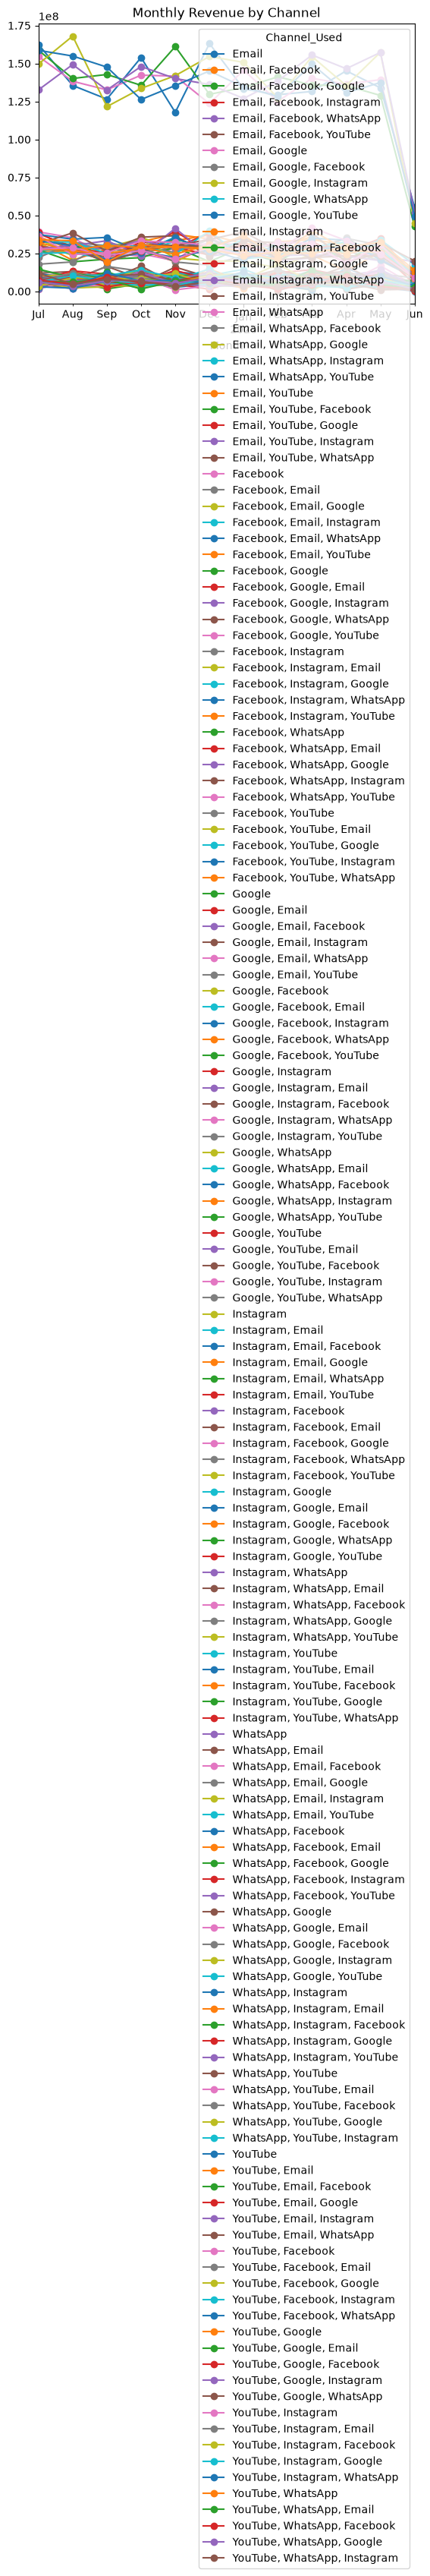

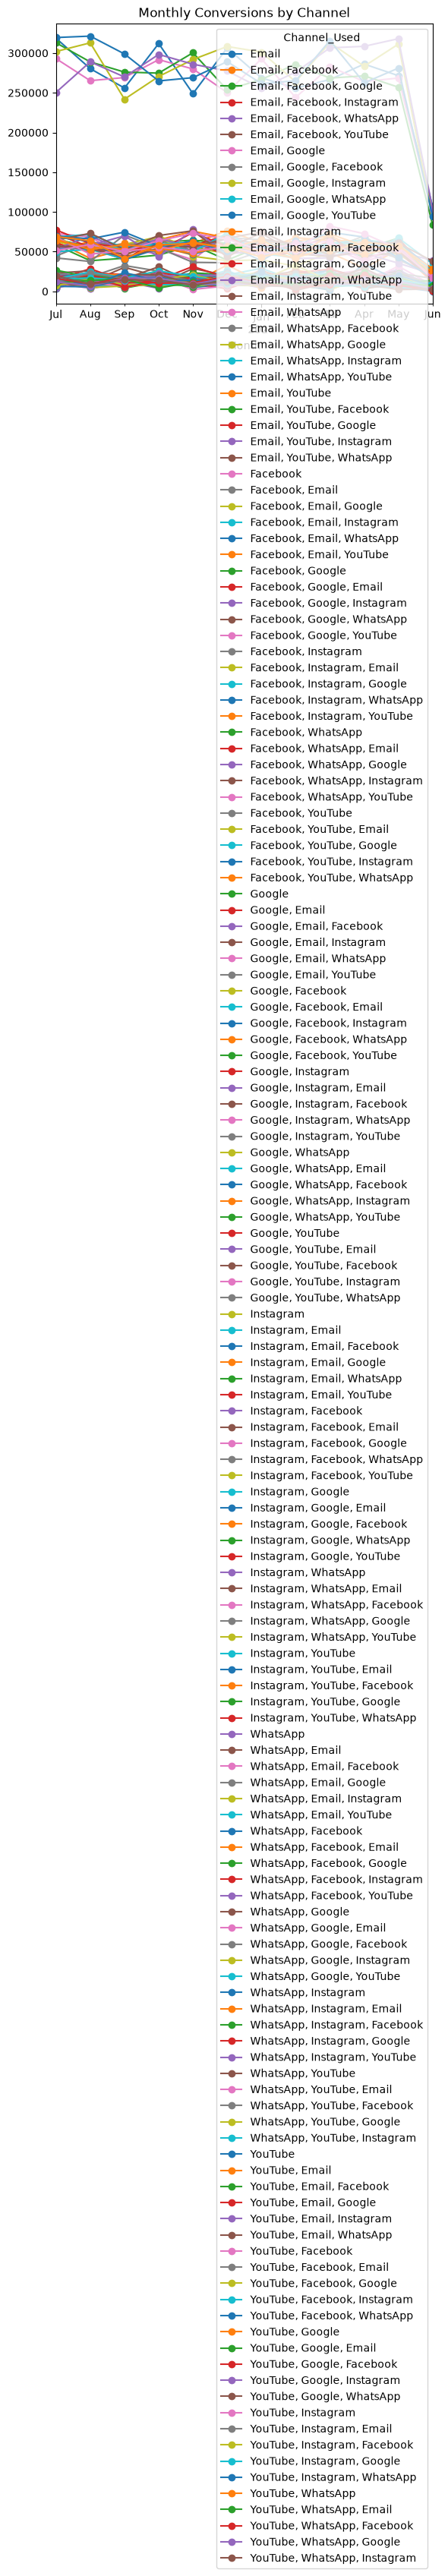

In [ ]:
monthly = (
    data.groupby(["Month", "Channel_Used"])[["Revenue", "Conversions"]]
        .sum()
        .reset_index()
)

# Pivot: one column per channel, ready for a line chart
rev_pivot  = monthly.pivot(index="Month", columns="Channel_Used", values="Revenue")
conv_pivot = monthly.pivot(index="Month", columns="Channel_Used", values="Conversions")

rev_pivot.plot(marker="o", title="Monthly Revenue by Channel")
conv_pivot.plot(marker="o", title="Monthly Conversions by Channel")

In [ ]:
data.describe()

,Duration,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,ROI,Engagement_Score,Date,Month_Num
count,55555.000000,55555.000000,55555.000000,55555.000000,55555.000000,5.555500e+04,55555.000000,55555.000000,55555.000000,55555,55555.000000
mean,17.446044,55087.885357,4688.070507,1877.271119,1032.866925,5.158197e+05,377.347068,2.713807,13.784169,2024-12-21 00:56:22.593825,6.555990
min,5.000000,10001.000000,202.000000,56.000000,19.000000,6.183000e+03,9.080000,-0.970000,2.600000,2024-07-01 00:00:00,1.000000
25%,11.000000,32680.000000,2110.000000,779.000000,400.000000,1.777060e+05,105.435000,0.040000,8.360000,2024-09-26 00:00:00,3.000000
50%,17.000000,55182.000000,3907.000000,1481.000000,779.000000,3.604360e+05,207.510000,1.240000,13.600000,2024-12-21 00:00:00,7.000000
75%,24.000000,77514.500000,6688.000000,2605.000000,1414.000000,6.874225e+05,428.580000,3.630000,18.855000,2025-03-17 00:00:00,10.000000
max,30.000000,100000.000000,14868.000000,8876.000000,6686.000000,4.579910e+06,15473.160000,74.420000,30.910000,2025-06-24 00:00:00,12.000000
std,7.520438,25930.001514,3178.686285,1435.636117,862.496788,4.900121e+05,541.084524,4.493380,6.353125,NaN,3.534795


In [ ]:
data.isnull().sum()

Campaign_ID         0
Campaign_Type       0
Target_Audience     0
Duration            0
Channel_Used        0
Impressions         0
Clicks              0
Leads               0
Conversions         0
Revenue             0
Acquisition_Cost    0
ROI                 0
Language            0
Engagement_Score    0
Customer_Segment    0
Date                0
Month               0
Month_Label         0
Month_Num           0
Month_Name          0
dtype: int64

In [ ]:
data.duplicated().sum()

np.int64(0)

## 2. Sales Performance


### 2.1 Total Revenue

In [ ]:
print("Total Revenue",data["Revenue"].sum())
print("revenue average",data["Revenue"].sum()/data["Campaign_ID"].count())

Total Revenue 28656364282
revenue average 515819.71527315275


### 2.2 Monthly Revenue

In [ ]:
data["month"] = data["Date"].dt.to_period("M")
data.head()

,Campaign_ID,Campaign_Type,Target_Audience,Duration,Channel_Used,Impressions,Clicks,Leads,Conversions,Revenue,...,ROI,Language,Engagement_Score,Customer_Segment,Date,Month,Month_Label,Month_Num,Month_Name,month
0,NY-CMP-1000,Social Media,College Students,21,"WhatsApp, YouTube",57804,6156,3616,2355,1867515,...,6.14,Hindi,20.98,College Students,2025-04-29,2025-04,Apr 2025,4,April,2025-04
1,NY-CMP-1001,Paid Ads,Tier 2 City Customers,18,YouTube,91801,3321,1971,1357,1046247,...,3.26,Hindi,7.24,College Students,2025-04-06,2025-04,Apr 2025,4,April,2025-04
2,NY-CMP-1002,Influencer,Youth,23,"WhatsApp, Google, YouTube",15536,2182,952,755,197055,...,1.88,English,25.03,College Students,2025-01-14,2025-01,Jan 2025,1,January,2025-01
3,NY-CMP-1003,Email,Working Women,18,"YouTube, Facebook, Instagram",88114,8413,2231,947,376906,...,0.60,Hindi,13.15,College Students,2025-06-04,2025-06,Jun 2025,6,June,2025-06
4,NY-CMP-1004,Paid Ads,College Students,10,"Facebook, Instagram",96871,3743,2060,1258,518296,...,0.80,Hindi,7.29,Tier 2 City Customers,2024-12-29,2024-12,Dec 2024,12,December,2024-12


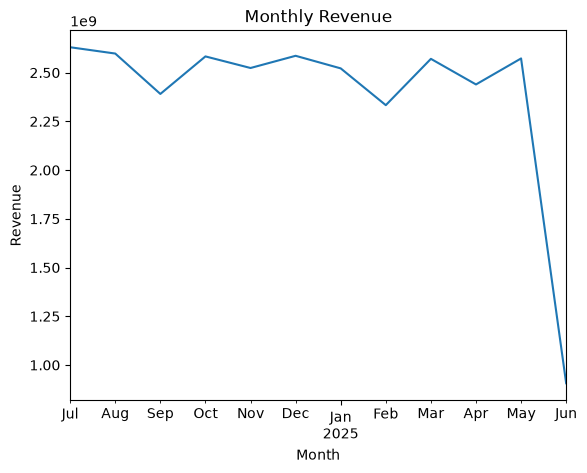

In [ ]:
data.groupby("month")["Revenue"].sum().plot(kind="line")
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.show()

### 2.3 Revenue Growth %

In [ ]:
monthly_revenue = data.groupby("month")["Revenue"].sum()
monthly_growth = monthly_revenue.pct_change() * 100

monthly_analysis = pd.DataFrame({
    "Revenue": monthly_revenue,
    "Growth %": monthly_growth
})

monthly_analysis

,Revenue,Growth %
month,,
2024-07,2630226313,NaN
2024-08,2597876736,-1.229916
2024-09,2390680030,-7.975617
2024-10,2583203421,8.053081
2024-11,2523763004,-2.301035
2024-12,2586353806,2.480059
2025-01,2521812438,-2.495458
2025-02,2333105678,-7.482982
2025-03,2570717938,10.184376


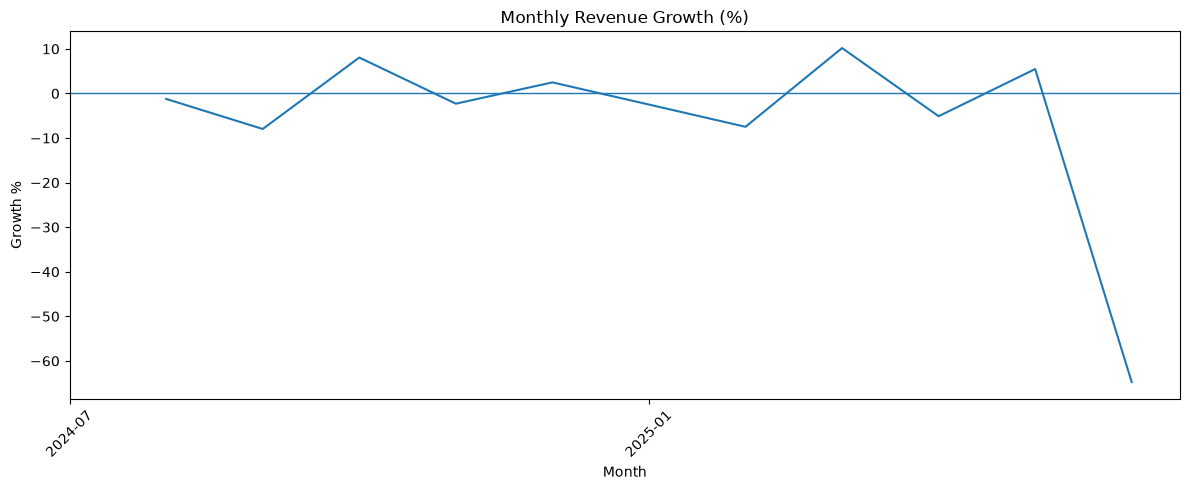

In [ ]:
plt.figure(figsize=(12,5))

plt.plot(
    monthly_growth.index.astype(str),
    monthly_growth.values
)

plt.title("Monthly Revenue Growth (%)")
plt.xlabel("Month")
plt.ylabel("Growth %")

plt.xticks(
    range(0, len(monthly_growth), 6),
    monthly_growth.index.astype(str)[::6],
    rotation=45
)

plt.axhline(0, linewidth=1)

plt.tight_layout()
plt.show()

### 2.4 Revenue by campaign type

In [ ]:
compaign_type_revenue=data.groupby("Campaign_Type")["Revenue"].sum()
compaign_type_revenue



Campaign_Type
Email           5685161788
Influencer      5769064044
Paid Ads        5751468983
SEO             5698831847
Social Media    5751837620
Name: Revenue, dtype: int64

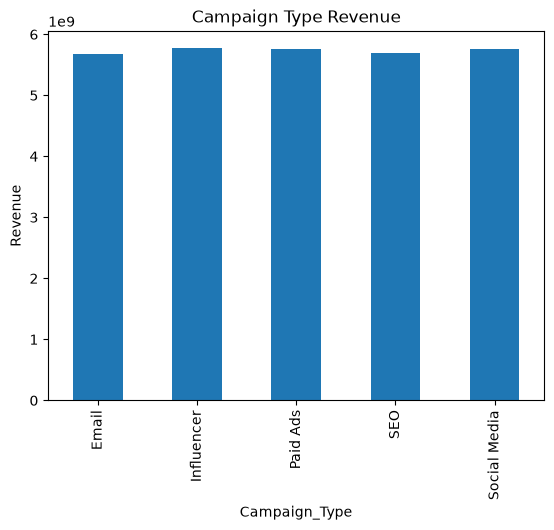

In [ ]:
compaign_type_revenue.plot(kind="bar")
plt.title("Campaign Type Revenue")
plt.xlabel("Campaign_Type")
plt.ylabel("Revenue")
plt.show()


### 2.5 AOV by compaign type

In [ ]:
aov_Campaign_Type = (
    data.groupby("Campaign_Type")["Revenue"]
    .sum()
    / data.groupby("Campaign_Type")["Campaign_ID"].nunique()
)

aov_Campaign_Type.sort_values(ascending=False)

Campaign_Type
Influencer      518148.378301
Social Media    517530.827785
Paid Ads        517404.550468
SEO             514381.428559
Email           511623.631030
dtype: float64

#### 2.6 Conversion Funnel Analysis
فين بنخسر أكبر نسبة من الجمهور خلال مراحل الحملة؟

In [ ]:

impressions = data["Impressions"].sum()
clicks = data["Clicks"].sum()
leads = data["Leads"].sum()
conversions = data["Conversions"].sum()

funnel_rates = pd.Series({
    "CTR (%)": clicks / impressions * 100 if impressions else np.nan,
    "Click to Lead (%)": leads / clicks * 100 if clicks else np.nan,
    "Lead to Conversion (%)": (
        conversions / leads * 100 if leads else np.nan
    )
})

display(funnel_rates.round(2))


CTR (%)                    8.51
Click to Lead (%)         40.04
Lead to Conversion (%)    55.02
dtype: float64

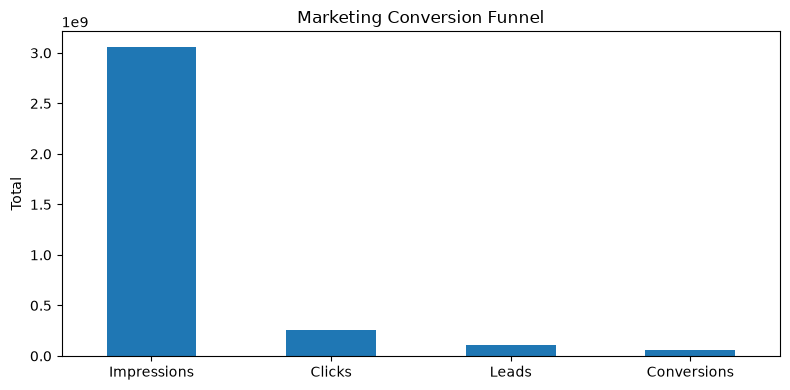

In [ ]:

funnel = pd.Series({
    "Impressions": impressions,
    "Clicks": clicks,
    "Leads": leads,
    "Conversions": conversions
})

funnel.plot(kind="bar", figsize=(8, 4))
plt.title("Marketing Conversion Funnel")
plt.ylabel("Total")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Language Analysis

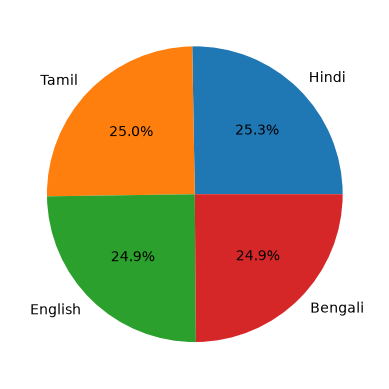

In [ ]:
language_revenue=data.groupby("Language")["Revenue"].sum().sort_values(ascending=False)
language_revenue.plot(kind="pie", autopct="%1.1f%%")
plt.show()

In [ ]:

language_analysis = data.groupby("Language").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Conversions=("Conversions", "sum"),
    Total_Leads=("Leads", "sum"),
    Average_ROI=("ROI", "mean")
).sort_values("Total_Revenue", ascending=False)

display(language_analysis.round(2))


,Total_Revenue,Total_Conversions,Total_Leads,Average_ROI
Language,,,,
Hindi,7242728156,14492037,26191087,2.76
Tamil,7151812108,14366885,26065537,2.68
English,7131128736,14225137,25977988,2.71
Bengali,7130695282,14296863,26057185,2.71


### Audience Analysis

In [ ]:

audience_analysis = data.groupby("Target_Audience").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Conversions=("Conversions", "sum"),
    Total_Leads=("Leads", "sum"),
    Average_Engagement=("Engagement_Score", "mean"),
    Records=("Campaign_ID", "count")
).sort_values("Total_Revenue", ascending=False)

display(audience_analysis.round(2))


,Total_Revenue,Total_Conversions,Total_Leads,Average_Engagement,Records
Target_Audience,,,,,
Premium Shoppers,5852284945,11703289,21254764,13.83,11182
College Students,5786247365,11579074,21024185,13.85,11078
Working Women,5743709729,11494222,20866491,13.81,11224
Tier 2 City Customers,5701063841,11419296,20787495,13.76,11100
Youth,5573058402,11185041,20358862,13.67,10971


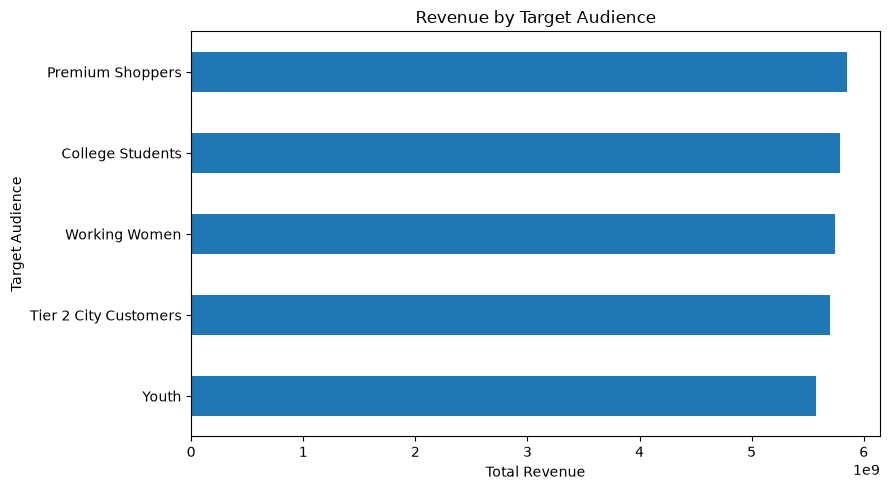

In [ ]:

audience_analysis["Total_Revenue"].sort_values().plot(
    kind="barh", figsize=(9, 5)
)
plt.title("Revenue by Target Audience")
plt.xlabel("Total Revenue")
plt.ylabel("Target Audience")
plt.tight_layout()
plt.show()


### Customer Segment Analysis

In [ ]:

segment_analysis = data.groupby("Customer_Segment").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Conversions=("Conversions", "sum"),
    Total_Leads=("Leads", "sum"),
    Average_Engagement=("Engagement_Score", "mean")
).sort_values("Total_Revenue", ascending=False)

display(segment_analysis.round(2))


,Total_Revenue,Total_Conversions,Total_Leads,Average_Engagement
Customer_Segment,,,,
Working Women,5811927015,11638803,21145512,13.87
College Students,5799502690,11583642,21060710,13.75
Premium Shoppers,5709910379,11445494,20755885,13.73
Tier 2 City Customers,5691846274,11365890,20677200,13.83
Youth,5643177924,11347093,20652490,13.73


### Cost & ROI Analysis , channel analsis

In [ ]:

channel_analysis = data.groupby("Channel_Used").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Conversions=("Conversions", "sum"),
    Total_Leads=("Leads", "sum"),
    Total_Cost=("Acquisition_Cost", "sum"),
    Average_ROI=("ROI", "mean")
)

channel_analysis = channel_analysis.sort_values(
    "Total_Revenue", ascending=False
)

channel_analysis.round(2)


,Total_Revenue,Total_Conversions,Total_Leads,Total_Cost,Average_ROI
Channel_Used,,,,,
Instagram,1639493563,3294211,5941320,1175344.99,2.74
WhatsApp,1615380939,3239706,5902521,1182375.14,2.82
YouTube,1597611646,3242976,5939026,1253669.14,2.63
Email,1587734385,3178048,5799945,1095921.12,2.79
Google,1586013727,3139859,5744089,1201528.71,2.58
...,...,...,...,...,...
"WhatsApp, Google, Instagram",62816889,124911,236479,54105.41,2.51
"YouTube, WhatsApp, Instagram",61106820,118114,212240,54841.69,2.45
"WhatsApp, YouTube, Google",60253318,126046,230996,55349.53,2.15


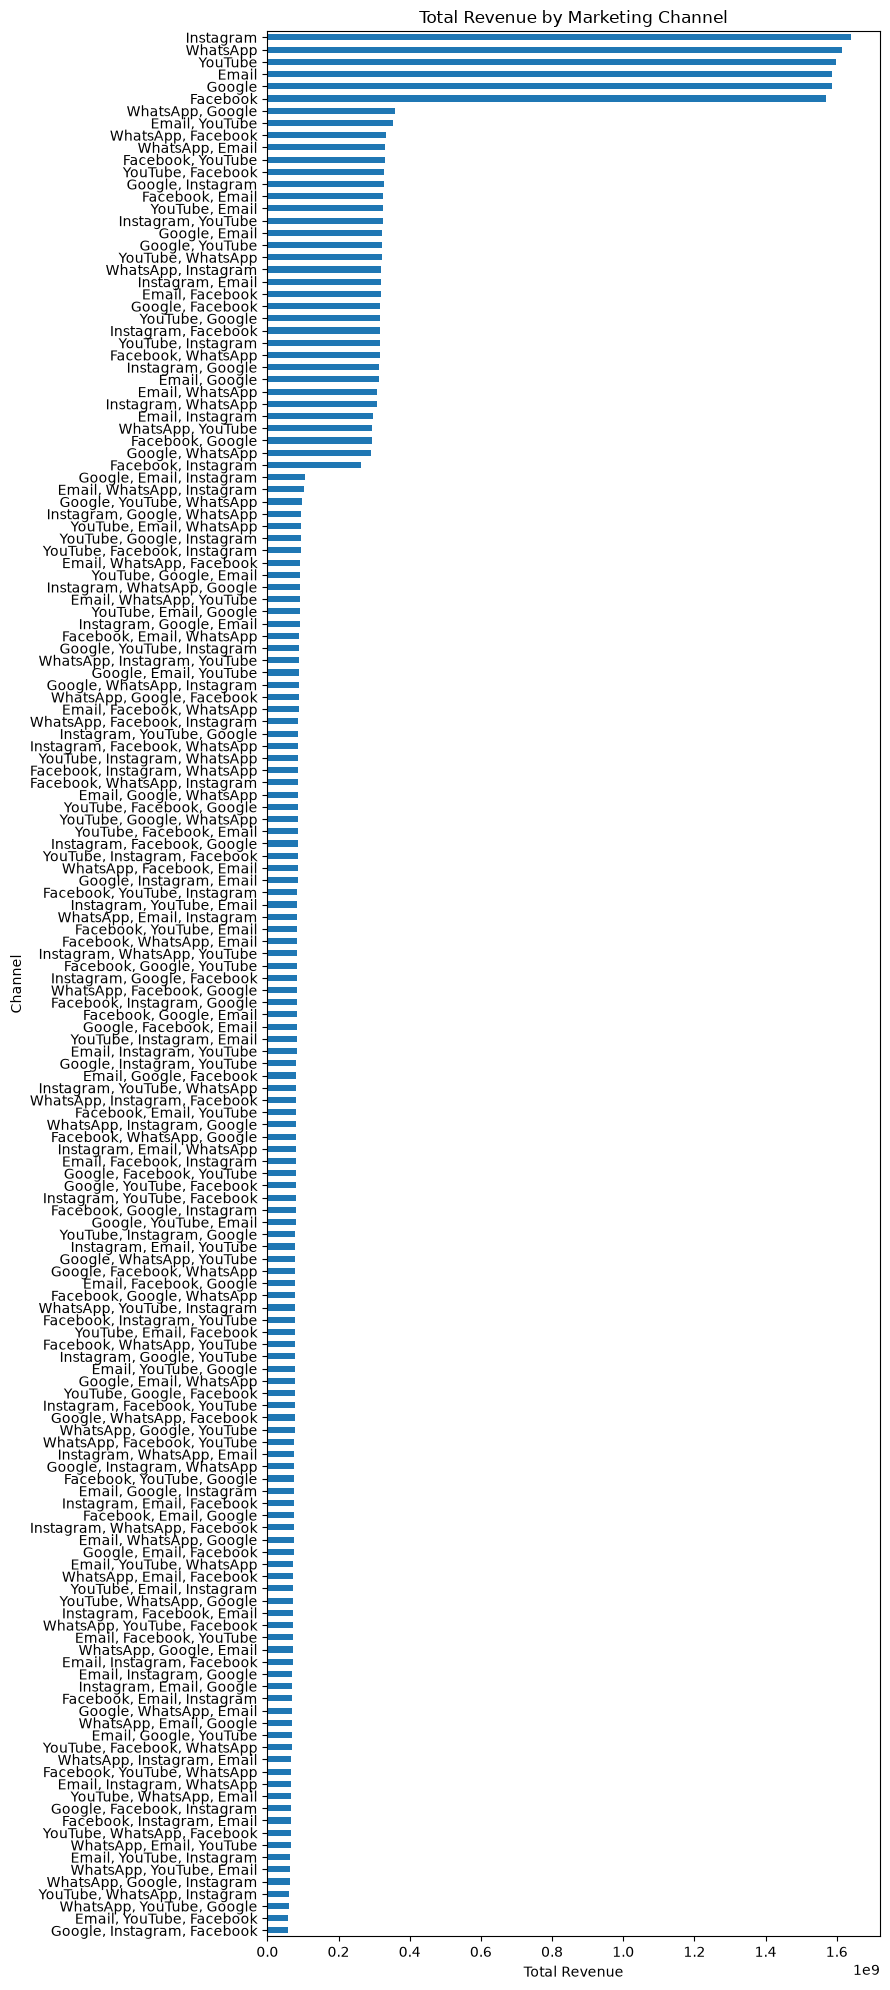

In [ ]:

channel_analysis["Total_Revenue"].sort_values().plot(
    kind="barh", figsize=(9,20)
)
plt.title("Total Revenue by Marketing Channel")
plt.xlabel("Total Revenue")
plt.ylabel("Channel")
plt.tight_layout()
plt.show()


In [ ]:
compaign_type_ROI=data.groupby("Campaign_Type")["ROI"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)
compaign_type_ROI

,count,mean,median,min,max
Campaign_Type,,,,,
Email,11112,2.68,1.21,-0.96,53.70
Influencer,11134,2.70,1.25,-0.95,66.32
Paid Ads,11116,2.72,1.22,-0.97,74.42
SEO,11079,2.71,1.25,-0.96,49.56
Social Media,11114,2.75,1.27,-0.97,54.74


### Campaign_Type_analysis

In [ ]:

Campaign_Type_analysis = data.groupby("Campaign_Type").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Conversions=("Conversions", "sum"),
    Total_Leads=("Leads", "sum"),
    Total_Cost=("Acquisition_Cost", "sum"),
    Average_ROI=("ROI", "mean")
)

Campaign_Type_analysis = Campaign_Type_analysis.sort_values(
    "Total_Revenue", ascending=False
)

Campaign_Type_analysis.round(2)


,Total_Revenue,Total_Conversions,Total_Leads,Total_Cost,Average_ROI
Campaign_Type,,,,,
Influencer,5769064044,11563919,20951392,4180655.95,2.70
Social Media,5751837620,11595675,21076766,4148449.24,2.75
Paid Ads,5751468983,11425573,20778836,4214354.89,2.72
SEO,5698831847,11369989,20763366,4196047.50,2.71
Email,5685161788,11425766,20721437,4224008.78,2.68


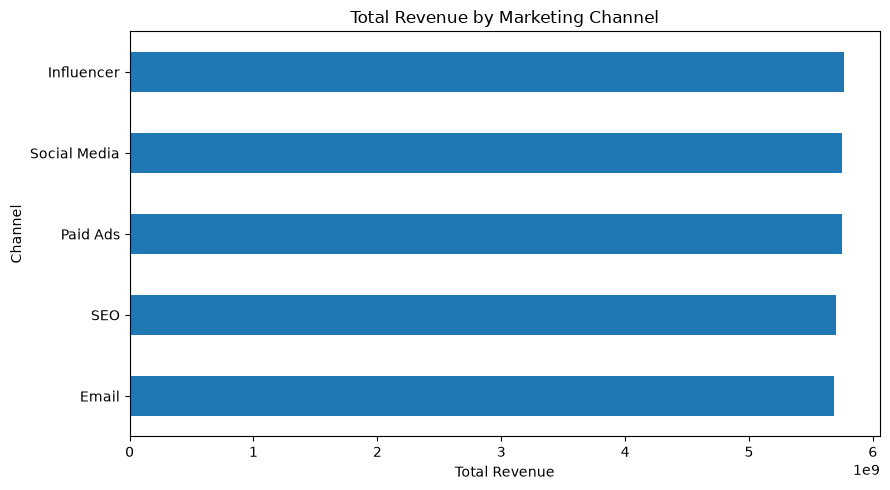

In [ ]:

Campaign_Type_analysis["Total_Revenue"].sort_values().plot(
    kind="barh", figsize=(9,5)
)
plt.title("Total Revenue by Marketing Channel")
plt.xlabel("Total Revenue")
plt.ylabel("Channel")
plt.tight_layout()
plt.show()


### Engagement Analysis

In [ ]:

engagement_analysis = data.groupby(
    pd.cut(data["Engagement_Score"], bins=5)
).agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Conversions=("Conversions", "sum"),
    Record_Count=("Engagement_Score", "count")
)

display(engagement_analysis.round(2))


,Total_Revenue,Total_Conversions,Record_Count
Engagement_Score,,,
"(2.572, 8.262]",2709313329,5401983,13618
"(8.262, 13.924]",5813863156,11652131,14982
"(13.924, 19.586]",8955316943,17874350,15033
"(19.586, 25.248]",8760272958,17652595,10095
"(25.248, 30.91]",2417597896,4799863,1827


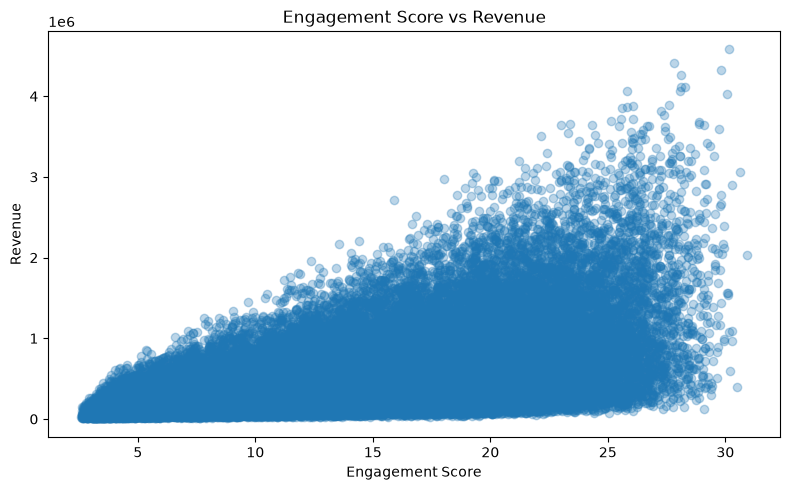

In [ ]:

plt.figure(figsize=(8, 5))
plt.scatter(data["Engagement_Score"], data["Revenue"], alpha=0.3)
plt.title("Engagement Score vs Revenue")
plt.xlabel("Engagement Score")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()


#### Time Analysis

C:\Users\Administrator\AppData\Local\Temp\ipykernel_13936\103855537.py:14: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


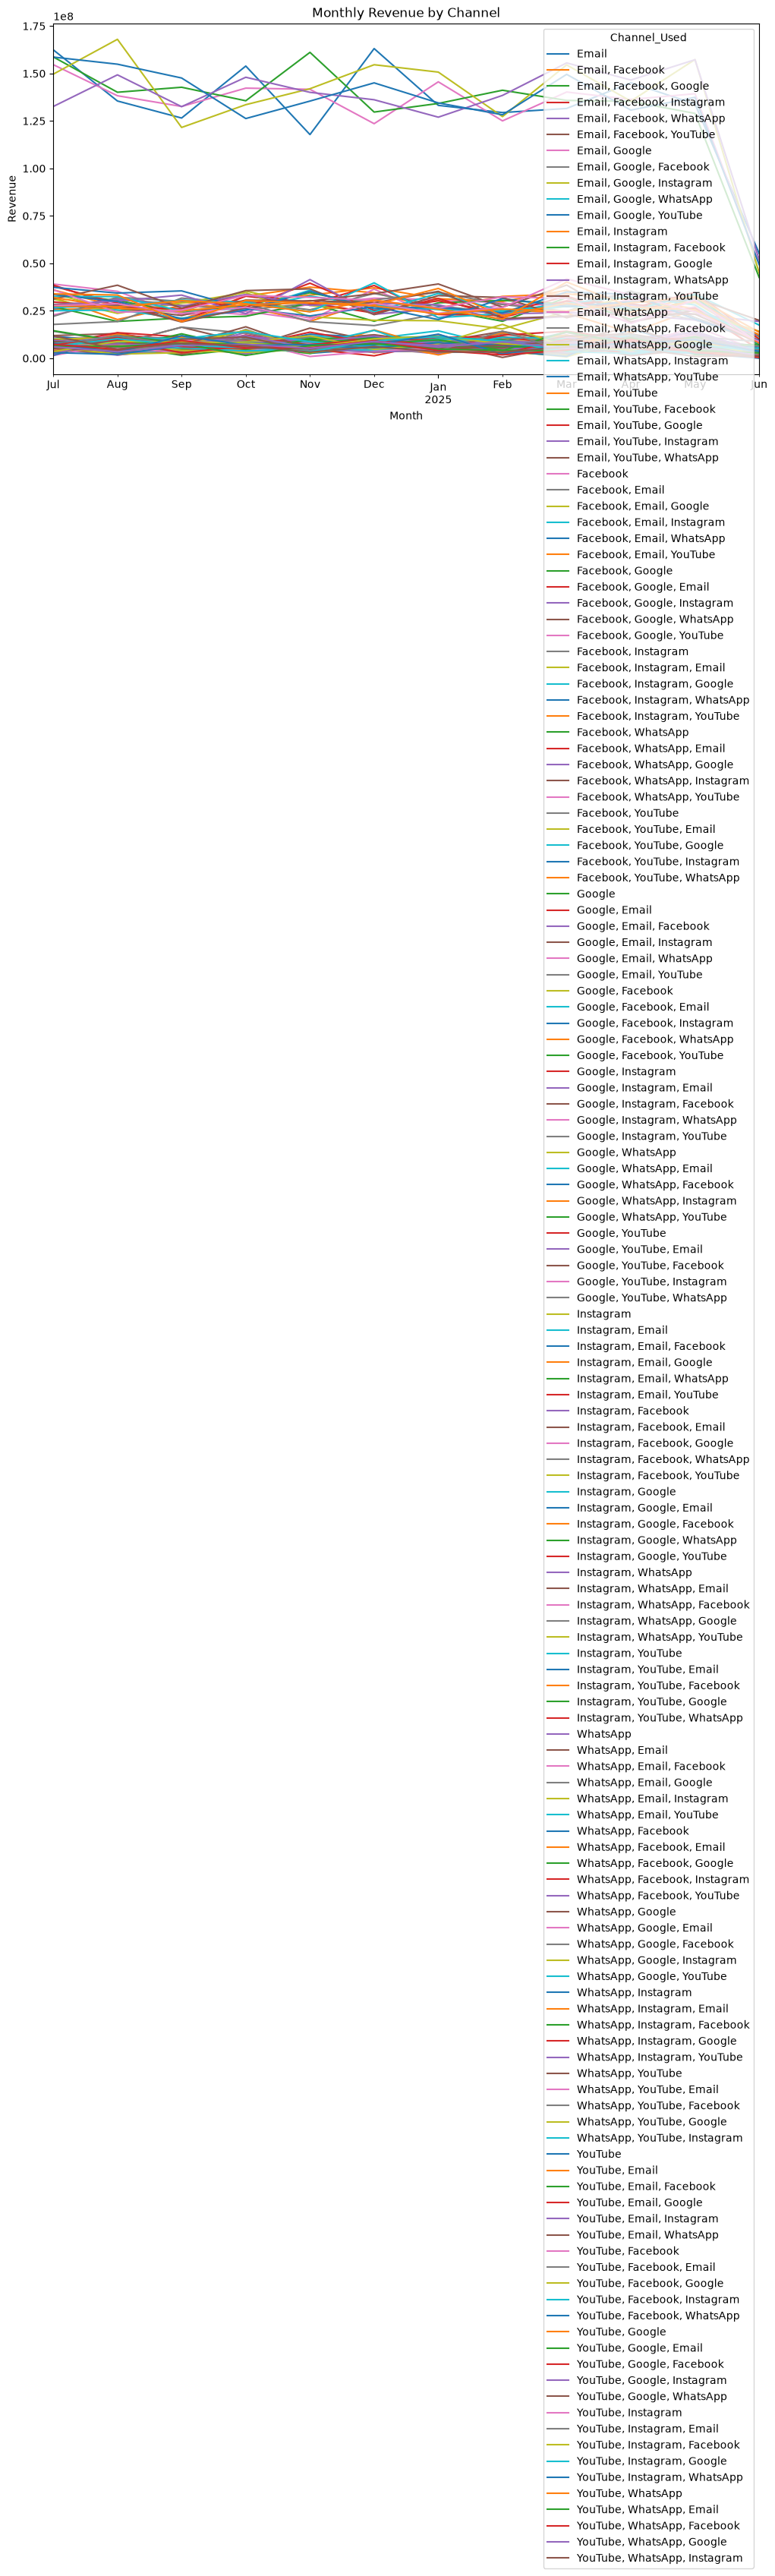

In [ ]:

data["Month"] = data["Date"].dt.to_period("M")

monthly_channel = data.pivot_table(
    index="Month",
    columns="Channel_Used",
    values="Revenue",
    aggfunc="sum"
)

monthly_channel.plot(figsize=(12, 6))
plt.title("Monthly Revenue by Channel")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()


### Duration Analysis

In [ ]:

duration_analysis = data.groupby("Duration").agg(
    Average_Revenue=("Revenue", "mean"),
    Average_Conversions=("Conversions", "mean"),
    Record_Count=("Duration", "count")
)

display(duration_analysis.sort_values("Duration").round(2))


,Average_Revenue,Average_Conversions,Record_Count
Duration,,,
5,511252.37,1033.04,2197
6,495300.49,1009.35,2118
7,513678.77,1024.37,2203
8,518673.87,1045.11,2205
9,515077.34,1020.91,2157
10,511862.83,1036.44,2164
11,517347.84,1032.84,2160
12,523880.18,1048.62,2062
13,524103.03,1056.31,2172


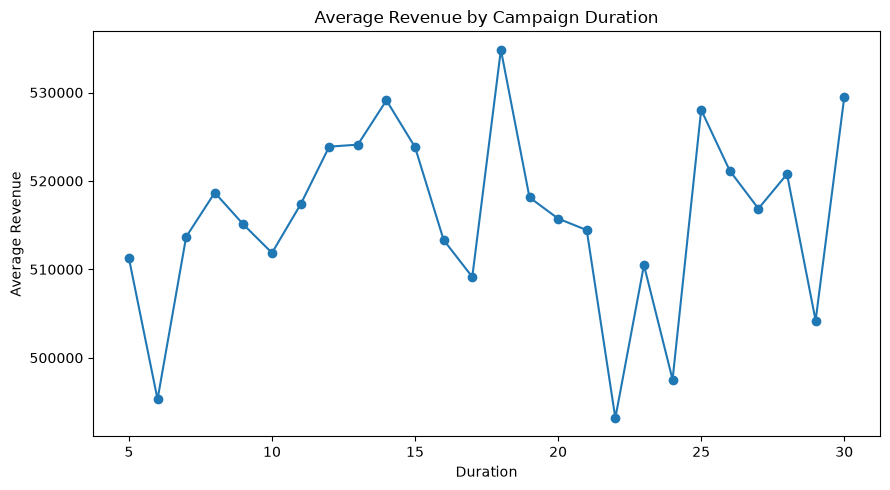

In [ ]:

duration_analysis["Average_Revenue"].plot(
    kind="line", marker="o", figsize=(9, 5)
)
plt.title("Average Revenue by Campaign Duration")
plt.xlabel("Duration")
plt.ylabel("Average Revenue")
plt.tight_layout()
plt.show()


### Correlation Analysis
ايه المؤشرات الرقمية اللي بتتحرك مع بعضها؟
لارتباط الموجب: المتغيران يميلان إلى الارتفاع معًا.
الارتباط السالب: أحدهما يميل للانخفاض عندما يرتفع الآخر.
الارتباط لا يثبت السببية.

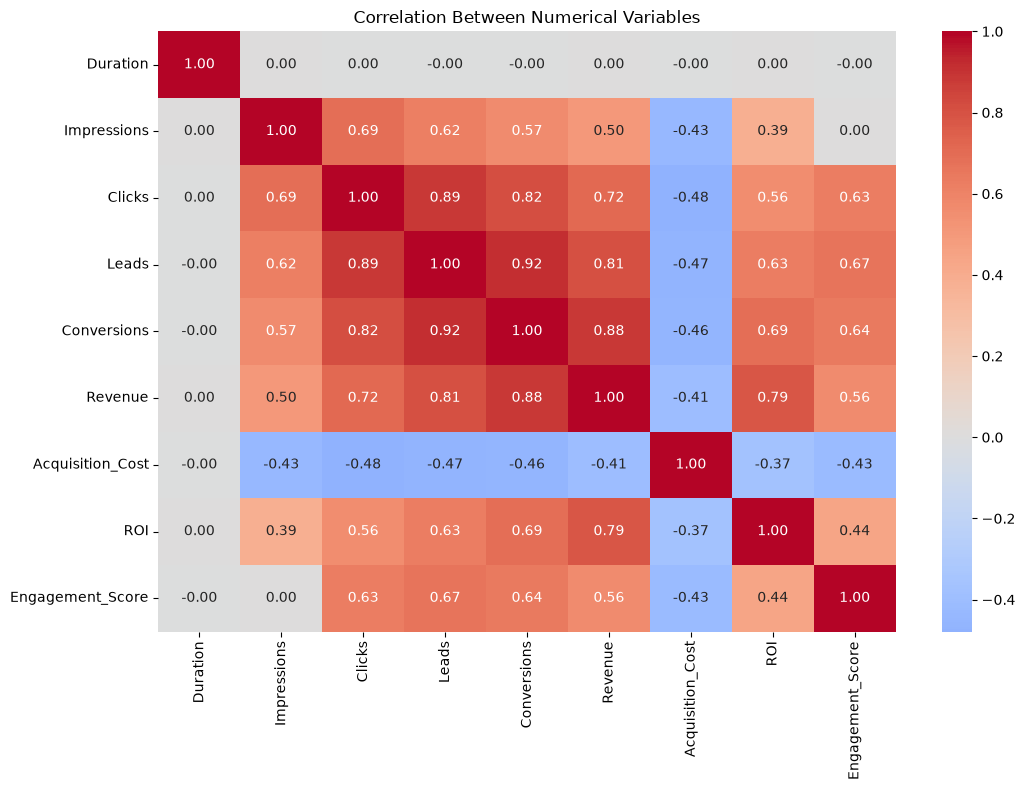

In [ ]:

numeric_columns = [
    "Duration",
    "Impressions",
    "Clicks",
    "Leads",
    "Conversions",
    "Revenue",
    "Acquisition_Cost",
    "ROI",
    "Engagement_Score"
]

correlation = data[numeric_columns].corr(numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()


In [ ]:
with pd.ExcelWriter("marketing_analysis_results.xlsx") as writer:
    channel_analysis.to_excel(writer, sheet_name="Channels")
    Campaign_Type_analysis.to_excel(writer, sheet_name="Campaign_Types")
    audience_analysis.to_excel(writer, sheet_name="Audiences")
    segment_analysis.to_excel(writer, sheet_name="Segments")
    language_analysis.to_excel(writer, sheet_name="Languages")
    channel_analysis.to_excel(writer, sheet_name="Cost_Analysis")
    monthly_analysis.to_excel(writer, sheet_name="Monthly_Revenue")
    engagement_analysis.to_excel(writer, sheet_name="Engagement")
    duration_analysis.to_excel(writer, sheet_name="Duration")

print("Analysis results saved.")


Analysis results saved.


In [41]:

revenue_by_channel = (
    data.groupby("Channel_Used", as_index=False)["Revenue"]
    .sum()
    .sort_values("Revenue", ascending=False)
)

display(revenue_by_channel)


,Channel_Used,Revenue
78,Instagram,1639493563
104,WhatsApp,1615380939
130,YouTube,1597611646
0,Email,1587734385
52,Google,1586013727
...,...,...
118,"WhatsApp, Google, Instagram",62816889
155,"YouTube, WhatsApp, Instagram",61106820
128,"WhatsApp, YouTube, Google",60253318
22,"Email, YouTube, Facebook",58148065


In [ ]:
data.to_csv(
    "ykaa_campaign_data_cleaned.csv",
    index=False
)